# Quy luật hành vi mua cho generator

**Mục tiêu:** rút ra từ dữ liệu thật các quy luật đơn giản để sinh dữ liệu cho shop thời trang của dự án. Mỗi quy luật gồm ba phần:

1. **Dữ liệu cho thấy gì:** biểu đồ hoặc bảng số đo thật.
2. **Quy luật:** một câu, ít tham số nhất có thể.
3. **Kiểm tra:** lấy mẫu theo quy luật rồi so với dữ liệu thật, sai lệch tính bằng điểm phần trăm.

| Nguồn | Phạm vi | Dùng cho |
|---|---|---|
| H&M | Kênh online, năm 2019 | Tần suất mua, khoảng cách mua lại, sản phẩm bán chạy, giỏ hàng, lịch |
| Olist | Đơn đặt năm 2017 | Lịch, giờ đặt hàng, điểm đánh giá theo giao trễ |

**Nguyên tắc chuyển nguồn:** chỉ đưa sang shop Việt Nam những quy luật **lặp lại giữa các nguồn** hoặc **dự báo đúng trên phần dữ liệu chưa dùng để ước lượng**. Con số gắn với một thị trường cụ thể (mùa sale châu Âu, thời gian giao ở Brazil) không được chuyển. Tham số không có dữ liệu được ghi là giả định ở mục 7.

In [1]:
%matplotlib inline
import datetime as dt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy import optimize, stats

repo_root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / ".git").exists())
data_dir = repo_root / "data" / "generator" / "eda" / "raw"
rng = np.random.default_rng(20260724)
plt.rcParams["figure.figsize"] = (10, 3.6)


def percent(values):
    return np.round(np.asarray(values) * 100, 1)

## 0. Dữ liệu

H&M: mỗi dòng là một đơn vị sản phẩm đã bán. `product_code` gồm 7 ký tự đầu của `article_id` (article = sản phẩm + màu). H&M không có mã đơn, nên **một đơn = một khách × một ngày** trên kênh online.

In [2]:
hm = (
    pl.scan_csv(
        data_dir / "hm" / "transactions_train.csv",
        schema_overrides={"article_id": pl.Utf8, "customer_id": pl.Utf8, "t_dat": pl.Utf8},
    )
    .with_columns(pl.col("t_dat").str.to_date())
    .filter((pl.col("t_dat").dt.year() == 2019) & (pl.col("sales_channel_id") == 2))
    .select(
        pl.col("customer_id").hash().alias("customer"),
        "t_dat",
        "article_id",
        pl.col("article_id").str.slice(0, 7).alias("product_code"),
        "price",
    )
    .collect(engine="streaming")
)
hm.select("t_dat", "price").describe()

statistic,t_dat,price
str,str,f64
"""count""","""11397400""",1.13974e7
"""null_count""","""0""",0.0
"""mean""","""2019-06-25 17:33:00.866092""",0.029942
"""std""",null,0.020498
"""min""","""2019-01-01""",0.000017
"""25%""","""2019-04-06""",0.016932
"""50%""","""2019-06-24""",0.025407
"""75%""","""2019-09-16""",0.033881
"""max""","""2019-12-31""",0.50678


**Nhận xét:** dữ liệu phủ trọn năm 2019 và không thiếu giá trị. `customer_id` được băm thành số để tiết kiệm bộ nhớ; phép băm chỉ dùng để nhóm. Giá giữ nguyên thang chuẩn hóa của nguồn, không đổi sang VND.

In [3]:
articles = (
    pl.read_csv(data_dir / "hm" / "articles.csv", schema_overrides={"article_id": pl.Utf8, "product_code": pl.Utf8})
    .select("product_code", "index_group_name", "product_group_name", "product_type_name")
    .unique("product_code")
)
olist_orders = pl.read_csv(data_dir / "olist" / "olist_orders_dataset.csv").with_columns(
    pl.col("order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date").str.to_datetime(
        strict=False
    )
).filter(pl.col("order_purchase_timestamp").dt.year() == 2017)
purchase_days = hm.select("customer", "t_dat").unique()
pl.DataFrame({"nguồn": ["H&M online 2019 (dòng)", "H&M đơn (khách × ngày)", "Olist 2017 (đơn)"],
              "số dòng": [hm.height, purchase_days.height, olist_orders.height]})

nguồn,số dòng
str,i64
"""H&M online 2019 (dòng)""",11397400
"""H&M đơn (khách × ngày)""",2682063
"""Olist 2017 (đơn)""",45101


## 1. Một khách mua bao nhiêu lần?


**Câu hỏi:** dữ liệu có ủng hộ giả định đơn giản nhất, "mọi khách mua với cùng một tốc độ" (phân phối Poisson), không? Nếu không, phân phối nào mô tả được?

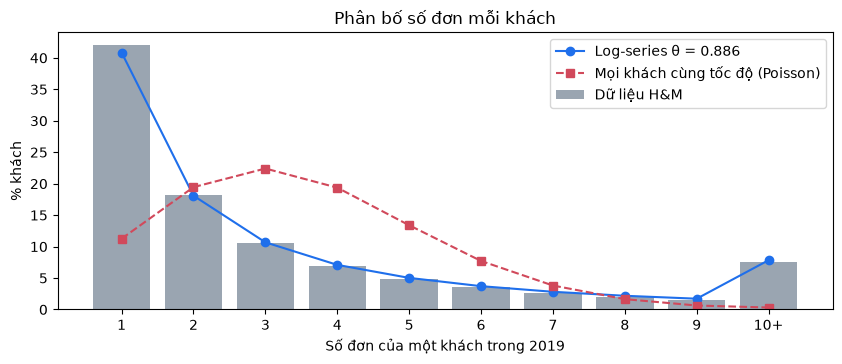

751,398 khách; trung bình 3.57 đơn/khách
Sai lệch lớn nhất (điểm %): log-series 1.0999999999999999 | Poisson 30.7


In [4]:
def customer_days(start, end):
    return (
        purchase_days.filter(pl.col("t_dat").is_between(start, end, closed="left"))
        .group_by("customer").len()["len"].to_numpy()
    )


def log_series_theta(mean):
    # Log-series có trung bình -θ/((1-θ)ln(1-θ)); θ là giá trị cho trung bình bằng dữ liệu.
    return optimize.brentq(lambda t: -t / ((1 - t) * np.log1p(-t)) - mean, 1e-9, 1 - 1e-12)


def log_series_pmf(k, theta):
    return -(theta**k) / (k * np.log1p(-theta))


orders_per_customer = customer_days(dt.date(2019, 1, 1), dt.date(2020, 1, 1))
theta12 = log_series_theta(orders_per_customer.mean())
same_rate = optimize.brentq(lambda lam: lam / (1 - np.exp(-lam)) - orders_per_customer.mean(), 1e-9, 1e3)

k = np.arange(1, 10)
observed = np.append([(orders_per_customer == i).mean() for i in k], (orders_per_customer >= 10).mean())
log_series = np.append(log_series_pmf(k, theta12), 1 - log_series_pmf(k, theta12).sum())
poisson = stats.poisson.pmf(k, same_rate) / (1 - np.exp(-same_rate))
poisson = np.append(poisson, 1 - poisson.sum())
labels = [str(i) for i in k] + ["10+"]
fig, ax = plt.subplots()
ax.bar(labels, observed * 100, color="#9aa5b1", label="Dữ liệu H&M")
ax.plot(labels, log_series * 100, "o-", color="#1f6feb", label=f"Log-series θ = {theta12:.3f}")
ax.plot(labels, poisson * 100, "s--", color="#d1495b", label="Mọi khách cùng tốc độ (Poisson)")
ax.set(xlabel="Số đơn của một khách trong 2019", ylabel="% khách", title="Phân bố số đơn mỗi khách")
ax.legend()
plt.show()
print(f"{len(orders_per_customer):,} khách; trung bình {orders_per_customer.mean():.2f} đơn/khách")
print("Sai lệch lớn nhất (điểm %): log-series", np.abs(observed - log_series).max().round(3) * 100,
      "| Poisson", np.abs(observed - poisson).max().round(3) * 100)

**Nhận xét:** 42% khách chỉ mua một lần và số khách giảm dần đều khi số đơn tăng. Giả định "mọi khách cùng tốc độ" sai lệch đến 31 điểm %: nó dự báo đa số khách mua 3–4 lần. Phân phối **log-series** chỉ có một tham số θ nhưng lệch tối đa khoảng 1 điểm %.

Vì vậy không cần chia ba nhóm khách theo tỷ lệ tự đặt: chỉ cần một tham số, phân phối đã tự sinh ra rất nhiều khách mua một lần và một nhóm nhỏ mua rất nhiều.

### 1.1. Lịch sử dài ngắn khác nhau thì sao?

Generator cho phép chọn số tháng lịch sử, nên θ phải đổi theo độ dài lịch sử T. Lý thuyết của phân phối này (mô hình NBD) cho công thức **θ = T/(α+T)**, trong đó α là hằng số. Kiểm tra: tính α chỉ từ 6 tháng đầu năm, rồi **dự báo** θ cho 3 tháng và 12 tháng và so với giá trị đo được.

In [5]:
windows = {"3 tháng": (dt.date(2019, 4, 1), 0.25), "6 tháng": (dt.date(2019, 7, 1), 0.5), "12 tháng": (dt.date(2020, 1, 1), 1.0)}
measured = {name: log_series_theta(customer_days(dt.date(2019, 1, 1), end).mean()) for name, (end, _) in windows.items()}
alpha_years = 0.5 * (1 - measured["6 tháng"]) / measured["6 tháng"]
predicted = {name: T / (alpha_years + T) for name, (_, T) in windows.items()}
k = np.arange(1, 4)
pl.DataFrame({
    "lịch sử": list(windows),
    "θ đo được": [round(measured[n], 3) for n in windows],
    "θ dự báo từ 6 tháng": [round(predicted[n], 3) for n in windows],
    "% khách mua 1 lần: đo": [percent((customer_days(dt.date(2019, 1, 1), end) == 1).mean()) for end, _ in windows.values()],
    "% khách mua 1 lần: dự báo": [percent(log_series_pmf(1, predicted[n])) for n in windows],
})

lịch sử,θ đo được,θ dự báo từ 6 tháng,% khách mua 1 lần: đo,% khách mua 1 lần: dự báo
str,f64,f64,f64,f64
"""3 tháng""",0.702,0.687,57.9,59.2
"""6 tháng""",0.814,0.814,48.4,48.4
"""12 tháng""",0.886,0.898,42.0,39.4


**Nhận xét:** với cùng một α ≈ 0,114 năm, công thức dự báo tỷ lệ khách mua một lần cho lịch sử 3 tháng (59% so với thực tế 58%) và 12 tháng (39% so với 42%), dù hai cửa sổ này không được dùng để tính α. Sai lệch 1–3 điểm % là đủ tốt để dùng một công thức cho mọi độ dài lịch sử.

**Quy luật R01:** số đơn của một khách đã mua theo **log-series, θ = T/(α+T), α = 0,114 năm** (T tính bằng năm). Tổng số đơn của dataset là **kết quả** của quy luật này, không còn là đầu vào.

## 2. Các đơn của một khách cách nhau bao lâu?

**Cách đơn giản nhất:** rải các đơn đều ngẫu nhiên trong cả năm. Nếu đúng, khách mua k lần có khoảng cách trung bình 365/(k+1) ngày.

c = 0.518; sai lệch lớn nhất so với trung bình thật (k = 2..30): 1.9%


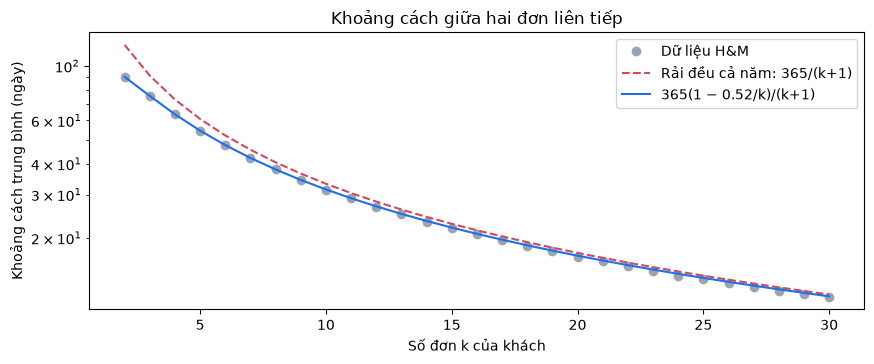

In [6]:
gaps = (
    purchase_days.sort("customer", "t_dat")
    .with_columns(gap=(pl.col("t_dat") - pl.col("t_dat").shift(1).over("customer")).dt.total_days(),
                  k=pl.len().over("customer"))
    .filter(pl.col("gap").is_not_null())
)
by_k = gaps.filter(pl.col("k") <= 30).group_by("k").agg(mean_gap=pl.col("gap").mean(), n=pl.len()).sort("k")
k_values, mean_gap, weight = (by_k[c].to_numpy() for c in ("k", "mean_gap", "n"))

# Mô hình: khoảng cách trung bình = 365(1 − c/k)/(k+1). Viết lại: mean_gap·(k+1)/365 = 1 − c·(1/k), tìm c bằng bình phương nhỏ nhất.
x, y = 1 / k_values, mean_gap * (k_values + 1) / 365
shrink_c = -(weight * x * (y - 1)).sum() / (weight * x * x).sum()
model_gap = 365 * (1 - shrink_c / k_values) / (k_values + 1)
print(f"c = {shrink_c:.3f}; sai lệch lớn nhất so với trung bình thật (k = 2..30): {np.abs(model_gap / mean_gap - 1).max():.1%}")
fig, ax = plt.subplots()
ax.plot(k_values, mean_gap, "o", color="#9aa5b1", label="Dữ liệu H&M")
ax.plot(k_values, 365 / (k_values + 1), "--", color="#d1495b", label="Rải đều cả năm: 365/(k+1)")
ax.plot(k_values, model_gap, "-", color="#1f6feb", label=f"365(1 − {shrink_c:.2f}/k)/(k+1)")
ax.set(xlabel="Số đơn k của khách", ylabel="Khoảng cách trung bình (ngày)", yscale="log", title="Khoảng cách giữa hai đơn liên tiếp")
ax.legend()
plt.show()

**Nhận xét:** khách mua nhiều lần thì đúng là rải gần đều cả năm. Khách mua ít lần thì các đơn **gần nhau hơn**: khách mua 2 lần có khoảng cách trung bình 90 ngày, trong khi rải đều cả năm cho 122 ngày. Lý do dễ hiểu là khách này không hoạt động trọn năm (mới biết đến shop hoặc thôi mua giữa chừng). Một hệ số c bù được phần này cho mọi k, sai số dưới 2%.

**Kiểm tra:** ngoài trung bình, quy luật có tái tạo đúng **tỷ lệ mua lại trong vòng 30 ngày** không? Mô hình giả định khoảng cách ngẫu nhiên kiểu "không nhớ" (phân phối mũ), nên tỷ lệ này bằng 1 − e^(−30/trung bình).

In [7]:
rows = []
for k_value in (2, 3, 5, 10, 20):
    g = gaps.filter(pl.col("k") == k_value)["gap"].to_numpy()
    model_mean = 365 * (1 - shrink_c / k_value) / (k_value + 1)
    rows.append({"k": k_value, "% mua lại ≤ 30 ngày: dữ liệu": percent((g <= 30).mean()),
                 "mô hình": percent(1 - np.exp(-30 / model_mean)),
                 "rải đều cả năm": percent(1 - np.exp(-30 * (k_value + 1) / 365))})
pl.DataFrame(rows)

k,% mua lại ≤ 30 ngày: dữ liệu,mô hình,rải đều cả năm
i64,f64,f64,f64
2,33.7,28.3,21.9
3,35.4,32.8,28.0
5,42.1,42.3,38.9
10,60.6,61.5,59.5
20,83.7,83.0,82.2


**Nhận xét:** từ k = 5 trở lên, mô hình lệch dưới 1 điểm %. Với khách mua 2–3 lần, mô hình vẫn thấp hơn thực tế khoảng 3–5 điểm % (khách thật mua lại sớm hơn một chút), nhưng gần thực tế hơn nhiều so với cách rải đều cả năm (thấp hơn 7–12 điểm %).

**Quy luật R02:** khoảng cách giữa hai đơn liên tiếp là ngẫu nhiên (phân phối mũ) với **trung bình T·(1 − c/k)/(k+1), c = 0,52**, trong đó T là số ngày lịch sử và k là số đơn của khách.

## 3. Sản phẩm nào bán chạy?


**Cohort:** sản phẩm H&M thuộc Ladieswear/Divided (shop của dự án bán thời trang nữ). Chỉ dùng sản phẩm **có bán trong cả 12 tháng**: hàng ra mắt hoặc ngừng bán giữa năm bán ít vì được bày bán ít ngày, không phải vì kém hấp dẫn. Catalog của generator bán suốt lịch sử, nên phải so với những sản phẩm có cùng điều kiện.

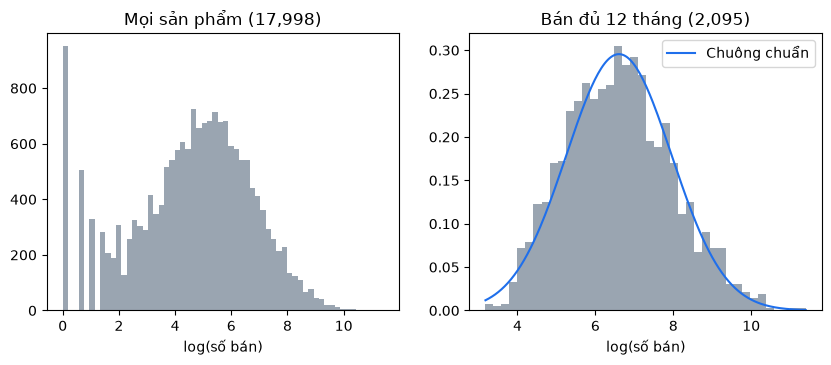

Độ lệch chuẩn của log(số bán), sản phẩm bán đủ năm: σ = 1.35


In [8]:
product_sales = (
    hm.group_by("product_code")
    .agg(units=pl.len(), months=pl.col("t_dat").dt.month().n_unique(), price=pl.col("price").median())
    .join(articles, on="product_code")
    .filter(pl.col("index_group_name").is_in(["Ladieswear", "Divided"]))
)
full_year = product_sales.filter(pl.col("months") == 12)["units"].to_numpy()
log_units = np.log(full_year)
sigma_popularity = log_units.std()
fig, ax = plt.subplots(1, 2)
ax[0].hist(np.log(product_sales["units"].to_numpy()), bins=60, color="#9aa5b1")
ax[0].set(xlabel="log(số bán)", title=f"Mọi sản phẩm ({product_sales.height:,})")
ax[1].hist(log_units, bins=40, density=True, color="#9aa5b1")
grid = np.linspace(log_units.min(), log_units.max(), 200)
ax[1].plot(grid, stats.norm.pdf(grid, log_units.mean(), sigma_popularity), color="#1f6feb", label="Chuông chuẩn")
ax[1].set(xlabel="log(số bán)", title=f"Bán đủ 12 tháng ({len(full_year):,})")
ax[1].legend()
plt.show()
print(f"Độ lệch chuẩn của log(số bán), sản phẩm bán đủ năm: σ = {sigma_popularity:.2f}")

**Nhận xét:** khi chỉ lấy sản phẩm bán đủ năm, log(số bán) có dạng **hình chuông** (phân phối log-normal). Đuôi trái dày ở biểu đồ bên trái đến từ hàng bày bán ngắn ngày. Toàn bộ mức chênh giữa hàng bán chạy và hàng bán chậm được mô tả bằng một số: **σ, độ lệch chuẩn của log(số bán)**.

**Kiểm tra:** lấy mẫu trọng số log-normal cho một catalog 60 hoặc 200 sản phẩm, rồi so tỷ trọng doanh số của top 10% và top 20% sản phẩm với các catalog cùng cỡ rút ngẫu nhiên từ H&M.

In [9]:
def top_share(weights, fraction):
    w = np.sort(weights)[::-1]
    return w[: max(1, int(len(w) * fraction))].sum() / w.sum()


rows = []
for n in (60, 200):
    model = np.mean([[top_share(rng.lognormal(0, sigma_popularity, n), f) for f in (0.1, 0.2)] for _ in range(500)], axis=0)
    real = np.mean([[top_share(rng.choice(full_year, n, replace=False), f) for f in (0.1, 0.2)] for _ in range(500)], axis=0)
    rows.append({"số sản phẩm": n, "top 10%: H&M": percent(real[0]), "top 10%: mô hình": percent(model[0]),
                 "top 20%: H&M": percent(real[1]), "top 20%: mô hình": percent(model[1])})
pl.DataFrame(rows)

số sản phẩm,top 10%: H&M,top 10%: mô hình,top 20%: H&M,top 20%: mô hình
i64,f64,f64,f64,f64
60,52.7,49.4,69.9,67.3
200,54.5,51.6,71.3,68.6


**Nhận xét:** catalog sinh theo quy luật có mức tập trung gần với H&M: top 10% sản phẩm chiếm khoảng một nửa doanh số. Mô hình thấp hơn khoảng 2–3,5 điểm %, tức hơi "đều" hơn thực tế một chút, và mức này chấp nhận được với một tham số đo trực tiếp.

### 3.1. Giá và nhóm hàng

In [10]:
print("Tương quan hạng (Spearman) giữa giá và số bán:", round(stats.spearmanr(product_sales["price"], product_sales["units"]).statistic, 3))
CATEGORY_TYPES = {
    "ao": ["Sweater", "Blouse", "Top", "T-shirt", "Vest top", "Shirt", "Cardigan", "Hoodie", "Bodysuit", "Polo shirt"],
    "khoac": ["Jacket", "Blazer", "Coat", "Outdoor Waistcoat", "Tailored Waistcoat"],
    "dam": ["Dress", "Jumpsuit/Playsuit", "Dungarees"],
    "vay": ["Skirt"],
    "quan": ["Trousers", "Shorts", "Leggings/Tights", "Outdoor trousers"],
    "tui-xach": ["Bag", "Weekend/Gym bag", "Shoulder bag", "Wallet"],
}
category = pl.when(pl.col("product_group_name") == "Shoes").then(pl.lit("giay"))
for code_name, types in CATEGORY_TYPES.items():
    category = category.when(pl.col("product_type_name").is_in(types)).then(pl.lit(code_name))
category = category.when(
    (pl.col("product_group_name") == "Accessories")
    & ~pl.col("product_type_name").is_in(["Dog Wear", "Giftbox", "Waterbottle", "Umbrella"])
).then(pl.lit("phu-kien"))
categorized = product_sales.with_columns(category=category)
print("Tỷ trọng số bán ngoài 8 nhóm của shop (đồ bơi, đồ lót, đồ ngủ, tất...):",
      percent(categorized.filter(pl.col("category").is_null())["units"].sum() / categorized["units"].sum()), "%")
category_table = (
    categorized.filter(pl.col("category").is_not_null())
    .group_by("category").agg(products=pl.len(), units=pl.col("units").sum())
    .with_columns(product_share=pl.col("products") / pl.col("products").sum(), demand_share=pl.col("units") / pl.col("units").sum())
    .with_columns(demand_multiplier=pl.col("demand_share") / pl.col("product_share"))
    .sort("demand_share", descending=True)
)
category_table.with_columns(pl.col("product_share", "demand_share", "demand_multiplier").round(3))

Tương quan hạng (Spearman) giữa giá và số bán: 0.012
Tỷ trọng số bán ngoài 8 nhóm của shop (đồ bơi, đồ lót, đồ ngủ, tất...): 20.4 %


category,products,units,product_share,demand_share,demand_multiplier
str,u32,u32,f64,f64,f64
"""ao""",5501,3354663,0.349,0.415,1.19
"""quan""",2134,1884214,0.135,0.233,1.723
"""dam""",3082,1401084,0.195,0.173,0.887
"""khoac""",1195,401862,0.076,0.05,0.656
"""vay""",897,373932,0.057,0.046,0.814
"""giay""",827,306829,0.052,0.038,0.724
"""phu-kien""",1754,282852,0.111,0.035,0.315
"""tui-xach""",384,75861,0.024,0.009,0.386


**Nhận xét:**
- **Giá không quyết định độ bán chạy:** tương quan bằng 0,01, nên generator không cần ràng buộc giá với độ phổ biến.
- **Nhóm hàng có ảnh hưởng:** quần bán gấp 1,7 lần mức trung bình mỗi sản phẩm, phụ kiện chỉ 0,3 lần. `product_share` dùng để chia số sản phẩm theo nhóm; `demand_multiplier` nhân vào trọng số log-normal.
- Việc ánh xạ loại sản phẩm của H&M sang 8 nhóm của shop là giả định. 20% số bán thuộc các nhóm shop không kinh doanh nên bị loại.

**Quy luật R03:** trọng số nhu cầu của mỗi sản phẩm = **LogNormal(0, σ = 1,35) × hệ số nhóm hàng**.

## 4. Một đơn có những gì?

Ba câu hỏi: đơn có bao nhiêu sản phẩm khác nhau, mỗi sản phẩm lấy bao nhiêu biến thể (màu), và mỗi biến thể bao nhiêu cái.

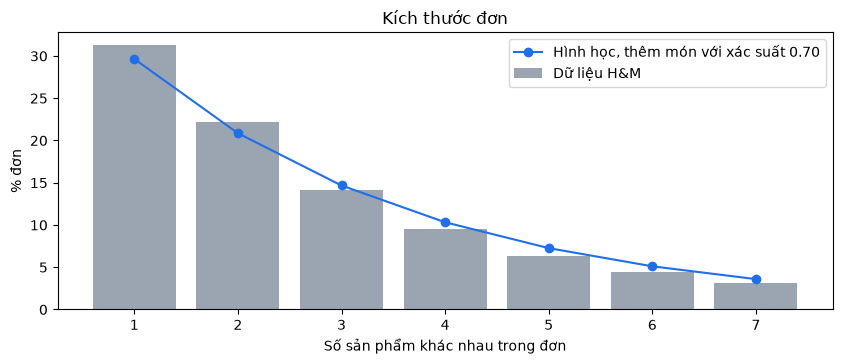

2,682,063 đơn; trung bình 3.37 sản phẩm; sai lệch lớn nhất 1.6 điểm %


Tương quan giữa kích thước đơn và số đơn của khách: 0.016


In [11]:
lines = hm.group_by("customer", "t_dat", "product_code", "article_id").agg(quantity=pl.len())
products_per_order = lines.group_by("customer", "t_dat").agg(products=pl.col("product_code").n_unique())
variants_per_product = lines.group_by("customer", "t_dat", "product_code").agg(variants=pl.len())["variants"].to_numpy()
quantity = lines["quantity"].to_numpy()

products = products_per_order["products"].to_numpy()
# Mô hình hình học: sau mỗi sản phẩm, khách thêm sản phẩm nữa với xác suất q; p = 1 − q = 1/trung bình.
p_stop = 1 / products.mean()
k = np.arange(1, 8)
geometric = p_stop * (1 - p_stop) ** (k - 1)
fig, ax = plt.subplots()
ax.bar([str(i) for i in k], [(products == i).mean() * 100 for i in k], color="#9aa5b1", label="Dữ liệu H&M")
ax.plot([str(i) for i in k], geometric * 100, "o-", color="#1f6feb", label=f"Hình học, thêm món với xác suất {1 - p_stop:.2f}")
ax.set(xlabel="Số sản phẩm khác nhau trong đơn", ylabel="% đơn", title="Kích thước đơn")
ax.legend()
plt.show()
print(f"{len(products):,} đơn; trung bình {products.mean():.2f} sản phẩm; sai lệch lớn nhất "
      f"{np.abs(np.array([(products == i).mean() for i in k]) - geometric).max() * 100:.1f} điểm %")
order_frequency = products_per_order.join(products_per_order.group_by("customer").len(), on="customer")
print("Tương quan giữa kích thước đơn và số đơn của khách:",
      round(stats.spearmanr(order_frequency["products"], order_frequency["len"]).statistic, 3))

In [12]:
def frequency_1_2_3(values):
    return percent([(values == 1).mean(), (values == 2).mean(), (values >= 3).mean()])


pl.DataFrame({"giá trị": ["1", "2", "3+"],
              "% biến thể của cùng sản phẩm": frequency_1_2_3(variants_per_product),
              "% số lượng mỗi biến thể": frequency_1_2_3(quantity)})

giá trị,% biến thể của cùng sản phẩm,% số lượng mỗi biến thể
str,f64,f64
"""1""",92.1,86.9
"""2""",7.0,11.6
"""3+""",1.0,1.4


**Nhận xét:**
- **Số sản phẩm trong đơn:** sau mỗi món, khách thêm món nữa với xác suất khoảng 70%. Quy luật một tham số này lệch tối đa khoảng 1,6 điểm %. Trung bình 3,4 sản phẩm mỗi đơn.
- **Biến thể và số lượng:** 92% sản phẩm chỉ lấy một màu và 87% biến thể chỉ mua một cái. Bảng tần suất 1 / 2 / 3+ là đủ, không cần mô hình.
- **Kích thước đơn không phụ thuộc khách** (tương quan 0,02), nên generator lấy mẫu đơn độc lập với khách.

**Giới hạn chuyển nguồn:** đơn H&M (shop một thương hiệu thời trang, gộp theo ngày) lớn hơn nhiều so với Olist (sàn thương mại, khoảng 93% đơn có một sản phẩm). Chọn H&M vì shop của dự án là shop một thương hiệu; đây là **giả định chuyển nguồn**.

**Quy luật R04:** số sản phẩm trong đơn theo **phân phối hình học, p = 0,30**; số biến thể và số lượng lấy theo bảng tần suất ở trên.

## 5. Đơn đến vào ngày nào, giờ nào?

**Cách đo hệ số ngày sale:** số đơn của ngày Black Friday chia cho **trung vị số đơn của 28 ngày trước đó**. Đo riêng ở từng nguồn để xem hiệu ứng có lặp lại không.

In [13]:
def daily_counts(frame, column):
    return frame.group_by(day=pl.col(column)).len().sort("day")


daily = {
    "H&M 2019": (daily_counts(purchase_days, "t_dat"), dt.date(2019, 11, 29)),
    "Olist 2017": (daily_counts(olist_orders.with_columns(day=pl.col("order_purchase_timestamp").dt.date()), "day"), dt.date(2017, 11, 24)),
}
rows = []
for name, (counts, black_friday) in daily.items():
    baseline = counts.filter(pl.col("day").is_between(black_friday - dt.timedelta(days=28), black_friday, closed="left"))["len"].median()
    event = counts.filter(pl.col("day") == black_friday)["len"].item()
    after = counts.filter(pl.col("day").is_between(black_friday + dt.timedelta(days=1), black_friday + dt.timedelta(days=3)))["len"].mean()
    rows.append({"nguồn": name, "đơn ngày thường (trung vị)": baseline, "đơn Black Friday": event,
                 "hệ số ngày sale": round(event / baseline, 2), "hệ số 3 ngày sau": round(after / baseline, 2)})
sale_table = pl.DataFrame(rows)
sale_table

nguồn,đơn ngày thường (trung vị),đơn Black Friday,hệ số ngày sale,hệ số 3 ngày sau
str,f64,i64,f64,f64
"""H&M 2019""",5814.5,32281,5.55,2.56
"""Olist 2017""",162.5,1176,7.24,2.65


In [14]:
weekday_rows = {}
for name, (counts, _) in daily.items():
    by_weekday = counts.group_by(weekday=pl.col("day").dt.weekday()).agg(pl.col("len").mean()).sort("weekday")["len"].to_numpy()
    weekday_rows[name] = np.round(by_weekday / by_weekday.mean(), 2)
pl.DataFrame({"thứ": ["T2", "T3", "T4", "T5", "T6", "T7", "CN"], **weekday_rows})

thứ,H&M 2019,Olist 2017
str,f64,f64
"""T2""",1.02,1.13
"""T3""",1.01,1.12
"""T4""",1.13,1.06
"""T5""",1.04,1.0
"""T6""",0.94,1.06
"""T7""",0.91,0.78
"""CN""",0.95,0.84


**Nhận xét:**
- **Ngày sale lớn là quy luật lặp lại:** ở hai shop thời trang (H&M, Olist), Black Friday có số đơn gấp 5,5 lần (H&M) và 7,2 lần (Olist) ngày thường, và ba ngày sau vẫn gấp khoảng 2,6 lần ở cả hai nguồn.
- **Thứ trong tuần không có quy luật chung:** H&M đông nhất vào thứ Tư và chỉ chênh khoảng ±10% giữa các ngày; Olist đông đầu tuần và vắng vào cuối tuần. Hai nguồn không cùng hình dạng, nên generator để các ngày trong tuần bằng nhau.
- Mùa vụ theo tháng của H&M (đỉnh tháng 6 do sale hè châu Âu) gắn với thị trường châu Âu nên không chuyển.

**Quy luật R05a:** ngày sale lớn nhân số đơn theo **trung bình hệ số ngày sale của H&M và Olist**; ba ngày sau nhân theo trung bình hệ số tương ứng. Áp cho 11.11, 12.12 và Black Friday ở Việt Nam là **giả định chuyển nguồn**. Tết và các ngày đôi nhỏ không có dữ liệu, nên là giả định.

Hệ số ngày sale (trung bình H&M + Olist): x6.39; ba ngày sau: x2.6


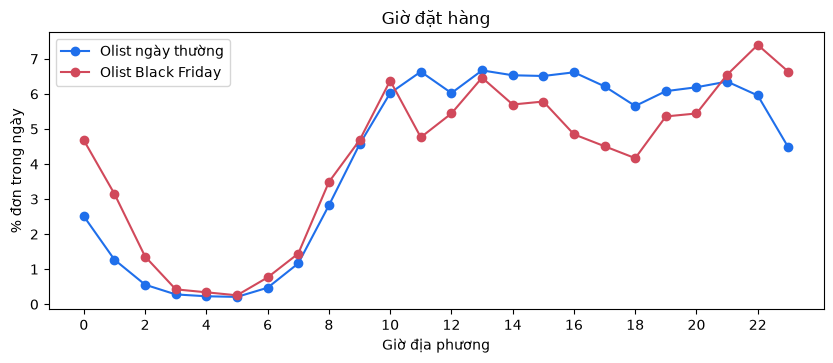

In [15]:
fashion = sale_table.filter(pl.col("nguồn").is_in(["H&M 2019", "Olist 2017"]))
sale_multiplier = round(fashion["hệ số ngày sale"].mean(), 2)
after_multiplier = round(fashion["hệ số 3 ngày sau"].mean(), 2)


def hour_share(frame, column, condition):
    counts = frame.filter(condition).group_by(hour=pl.col(column).dt.hour()).len().sort("hour")["len"].to_numpy()
    return counts / counts.sum()


olist_day = pl.col("order_purchase_timestamp").dt.date() == dt.date(2017, 11, 24)
olist_normal = hour_share(olist_orders, "order_purchase_timestamp", ~olist_day)
olist_sale = hour_share(olist_orders, "order_purchase_timestamp", olist_day)
print(f"Hệ số ngày sale (trung bình H&M + Olist): x{sale_multiplier}; ba ngày sau: x{after_multiplier}")
fig, ax = plt.subplots()
ax.plot(olist_normal * 100, "-o", color="#1f6feb", label="Olist ngày thường")
ax.plot(olist_sale * 100, "-o", color="#d1495b", label="Olist Black Friday")
ax.set(xlabel="Giờ địa phương", ylabel="% đơn trong ngày", xticks=range(0, 24, 2), title="Giờ đặt hàng")
ax.legend()
plt.show()

**Nhận xét:** ngày thường, đơn Olist rải đều từ 10h đến 23h. Vào ngày sale có thêm **đỉnh lúc 0–1h** (gần gấp đôi ngày thường), đúng với thói quen "săn sale lúc nửa đêm".

**Quy luật R05b:** giờ đặt hàng lấy theo phân bố của Olist, với hai phân bố riêng cho ngày thường và ngày sale. Chọn Olist vì đây là thương mại điện tử tiêu dùng, đơn tập trung buổi tối; dùng cho Việt Nam là **giả định chuyển nguồn**.

## 6. Giao trễ ảnh hưởng điểm đánh giá thế nào?

**Cohort:** đơn Olist 2017 đã giao và có đánh giá. Đơn trễ là đơn giao sau ngày hẹn. Đo trực tiếp phân phối số sao theo số ngày trễ.

In [16]:
reviews = (
    pl.read_csv(data_dir / "olist" / "olist_order_reviews_dataset.csv")
    .group_by("order_id").agg(score=pl.col("review_score").cast(pl.Int64).first())
)
delivered = (
    olist_orders.filter((pl.col("order_status") == "delivered") & pl.col("order_delivered_customer_date").is_not_null())
    .with_columns(late_days=(pl.col("order_delivered_customer_date").dt.date() - pl.col("order_estimated_delivery_date").dt.date())
                  .dt.total_days().clip(lower_bound=0))
    .join(reviews, on="order_id", how="inner")
    .with_columns(late_bucket=pl.when(pl.col("late_days") == 0).then(pl.lit("on_time"))
                  .when(pl.col("late_days") <= 3).then(pl.lit("late_1_3"))
                  .when(pl.col("late_days") <= 7).then(pl.lit("late_4_7"))
                  .otherwise(pl.lit("late_8_plus")))
)
late = delivered.filter(pl.col("late_days") > 0)
print(f"{delivered.height:,} đơn; trễ hẹn {percent((delivered['late_days'] > 0).mean())}%")
print("Trong các đơn trễ:", {b: percent((late["late_bucket"] == b).mean()) for b in ("late_1_3", "late_4_7", "late_8_plus")})
rating_table = (
    delivered.group_by("late_bucket")
    .agg(orders=pl.len(), **{f"{star}_sao_%": ((pl.col("score") == star).mean() * 100).round(1) for star in range(1, 6)})
    .sort(pl.col("late_bucket").replace_strict({"on_time": 0, "late_1_3": 1, "late_4_7": 2, "late_8_plus": 3}))
)
rating_table

43,098 đơn; trễ hẹn 5.5%
Trong các đơn trễ: {'late_1_3': np.float64(29.2), 'late_4_7': np.float64(26.6), 'late_8_plus': np.float64(44.3)}


late_bucket,orders,1_sao_%,2_sao_%,3_sao_%,4_sao_%,5_sao_%
str,u32,f64,f64,f64,f64,f64
"""on_time""",40714,6.4,2.8,8.4,20.8,61.6
"""late_1_3""",695,26.2,7.8,13.4,19.9,32.8
"""late_4_7""",633,55.9,8.8,10.1,7.7,17.4
"""late_8_plus""",1056,68.1,9.8,8.4,5.3,8.4


**Nhận xét:** giao đúng hẹn thì 62% khách chấm 5 sao. Trễ 1–3 ngày, tỷ lệ 5 sao giảm còn khoảng một phần ba. Trễ trên một tuần, khoảng 2/3 khách chấm 1 sao. Mức giảm **mạnh nhất ở những ngày trễ đầu tiên**, sau đó chững lại. Đây là số đo trực tiếp, nên generator dùng thẳng bảng này mà không cần mô hình.

Không chuyển sang Việt Nam:
- **Thời gian giao:** trung vị khoảng 11 ngày phản ánh khoảng cách địa lý ở Brazil, nên thời gian giao ở Việt Nam là giả định.
- **Tỷ lệ viết đánh giá:** gần 100% vì Olist gửi khảo sát cho mọi đơn, nên là giả định.

**Quy luật R06:** điểm đánh giá lấy theo bảng số sao của mức trễ tương ứng. Tỷ lệ đơn trễ và cách chia mức trễ lấy từ Olist (chuyển nguồn).

## 7. Phần không có dữ liệu: tham số kịch bản

Các nguồn trên **không đo được** những tham số dưới đây cho một shop Việt Nam. Chúng được giữ làm tham số kịch bản, ghi rõ là giả định, không trình bày như quy luật:

| Nhóm | Tham số | Vì sao không có số đo |
|---|---|---|
| Thanh toán | Tỷ trọng COD | Olist là thẻ tín dụng Brazil; khảo sát Việt Nam đo theo người trả lời, không theo đơn |
| Kết quả đơn | Tỷ lệ hủy, giao COD thất bại, trả/đổi hàng | Không nguồn nào có dữ liệu đổi trả; tỷ lệ hủy của sàn Olist không tương đương |
| Khuyến mại | Tỷ lệ dùng mã, mức giảm | Không nguồn nào ghi nhận việc dùng mã giảm giá |
| Giao hàng | Số ngày giao ở Việt Nam | Thời gian giao Olist phản ánh địa lý Brazil |
| Đánh giá | Tỷ lệ viết đánh giá | Olist gửi khảo sát cho mọi đơn |
| Lịch Việt Nam | Tết, các ngày đôi nhỏ | Không có dữ liệu Việt Nam theo ngày |
| Khách | Số tài khoản chưa từng mua | H&M chỉ có khách đã mua trong năm |

### 7.1. Đối chiếu với số liệu Việt Nam công khai

Số liệu e-commerce Việt Nam công khai chỉ có ở mức **tổng thị trường** hoặc **thông cáo của sàn**, không có ở mức đơn hàng. Vì vậy chúng không đủ để ước lượng tham số, chỉ dùng để kiểm tra các tham số hiện tại có hợp lý không.

| Tham số trong generator | Số liệu Việt Nam | Mức tin cậy của nguồn | Kết luận |
|---|---|---|---|
| Ngày sale ×6,39 (R05) | Shopee 11.11/2021: lượt truy cập 2 giờ đầu ×5,5; nhà bán lần đầu ×18 đơn [1]. Thông cáo Shopee (không rõ năm): nhà bán trong nước ×10 đơn | Thông cáo của sàn, mỗi số đo một chỉ số khác nhau | ×6,39 nằm trong khoảng các sàn công bố; giữ nguyên |
| Giờ đặt hàng theo Olist (R05) | Báo cáo Tết 2026 của Shopee: ưu tiên buổi trưa, 20h, 21h; trước đây flash sale lúc khuya chiếm ưu thế [2] | Báo cáo của sàn, chỉ định tính | Phù hợp với phân bố Olist (trưa đến tối, đỉnh 0–1h ngày sale); giữ nguyên |
| Giá sản phẩm (`price_bands`) | Metric, thời trang nữ tháng 10/2025: 3.934 tỷ đồng; bài dẫn lại ghi cả 33 triệu lẫn 19 triệu sản phẩm, tức khoảng 119.000–207.000 đ/sản phẩm [3] | Tin dẫn lại, số liệu tự mâu thuẫn | Hạ giá giả định về trung bình khoảng 234.000 đ, cao hơn mặt bằng sàn một chút vì là shop thương hiệu |
| Số ngày giao | iPrice/Parcel Perform, 80.000 đơn: Việt Nam trung bình 5–6 ngày [4] | Không rõ năm khảo sát | Đổi giả định giao đúng hẹn thành 2–6 ngày |
| COD, tỷ lệ hoàn hàng (mục 7) | Blog GHTK: COD hơn 80%, hoàn hàng 15–20% [5] | Không trích dẫn nguồn gốc; đơn vị viết có lợi ích thương mại | Không dùng; giữ là tham số kịch bản |

Nguồn:
1. [Bizhub — Shopee 11.11 Big Sale 2021](https://bizhub.vietnamnews.vn/shopee-says-1111-big-sale-beats-last-years-record-post329083.html)
2. [VietNamNet — Báo cáo Tết 2026 của Shopee](https://vietnamnet.vn/en/gen-z-and-gen-y-reshape-tet-shopping-habits-online-2487854.html)
3. [Brands Vietnam — Thời trang nữ trên TMĐT (dẫn Metric)](https://www.brandsvietnam.com/congdong/topic/thoi-trang-nu-tang-nhiet-xu-huong-nao-dang-do-bo-mua-thu-dong)
4. [Brands Vietnam — Báo cáo ngành giao vận TMĐT (iPrice/Parcel Perform)](https://www.brandsvietnam.com/congdong/topic/17271-Bao-cao-nganh-giao-van-TMDT-Viet-Nam-xep-ap-chot-khu-vuc-ve-toc-do-giao-hang)
5. [GHTK — Ship COD](https://ghtk.vn/blog/ship-cod/)

## 8. Tổng hợp

| Mã | Hành vi | Quy luật | Tham số | Kiểm tra | Phạm vi chuyển nguồn |
|---|---|---|---|---|---|
| R01 | Số đơn mỗi khách | Log-series, θ = T/(α+T) | α | Lệch ≈ 1 điểm %; dự báo 3 và 12 tháng lệch 1–3 điểm % | Dạng quy luật kinh điển của bán lẻ; α lấy từ H&M |
| R02 | Khoảng cách giữa các đơn | Ngẫu nhiên, trung bình T(1 − c/k)/(k+1) | c | Tỷ lệ mua lại trong 30 ngày lệch ≤ 1 điểm % từ k = 5, 3–5 điểm % ở k = 2–3 | Hệ quả của R01 |
| R03 | Sản phẩm bán chạy | LogNormal(σ) × hệ số nhóm | σ, hệ số nhóm | Tỷ trọng top 10%/20% lệch 2–3,5 điểm % | Ánh xạ nhóm hàng là giả định |
| R04 | Kích thước đơn | Hình học; bảng tần suất biến thể và số lượng | p | Lệch ≤ 1,6 điểm %; độc lập với khách | H&M (shop một thương hiệu) thay cho Olist |
| R05 | Lịch | Hệ số ngày sale; các ngày trong tuần bằng nhau; giờ theo Olist | Hệ số sale, phân bố giờ | Lặp lại ở H&M và Olist | Áp cho 11.11/12.12 là giả định |
| R06 | Điểm đánh giá | Bảng số sao theo mức trễ | Bảng 4 × 5 | Số đo trực tiếp | Tỷ lệ trễ từ Olist; thời gian giao VN là giả định |

Ô dưới in các tham số theo đúng khóa của `generator/oltp/configs/1m.yml`, để đối chiếu khi cập nhật cấu hình.

In [17]:
import json

parameters = {
    "customers.purchase_frequency.alpha_years": round(alpha_years, 4),
    "customers.repeat_gap.shrink_c": round(shrink_c, 3),
    "products.popularity.sigma": round(sigma_popularity, 3),
    "products.categories": {row["category"]: {"product_share": round(row["product_share"], 4),
                                              "demand_multiplier": round(row["demand_multiplier"], 3)}
                            for row in category_table.iter_rows(named=True)},
    "baskets.products.p": round(p_stop, 3),
    "baskets.variants_per_product": frequency_1_2_3(variants_per_product).tolist(),
    "baskets.quantity_per_variant": frequency_1_2_3(quantity).tolist(),
    "calendar.sale_events": {"event_day_multiplier": sale_multiplier, "after_days": 3, "after_multiplier": after_multiplier},
    "calendar.hour_of_day": {"normal": np.round(olist_normal, 4).tolist(), "sale_day": np.round(olist_sale, 4).tolist()},
    "fulfilment.late_rate": round((delivered["late_days"] > 0).mean(), 3),
    "fulfilment.late_buckets_%": {b: percent((late["late_bucket"] == b).mean()) for b in ("late_1_3", "late_4_7", "late_8_plus")},
    "reviews.rating_by_lateness_%": {row["late_bucket"]: [row[f"{s}_sao_%"] for s in range(1, 6)] for row in rating_table.iter_rows(named=True)},
}
print(json.dumps(parameters, ensure_ascii=False, indent=1, default=float))

{
 "customers.purchase_frequency.alpha_years": 0.1141,
 "customers.repeat_gap.shrink_c": 0.518,
 "products.popularity.sigma": 1.35,
 "products.categories": {
  "ao": {
   "product_share": 0.3487,
   "demand_multiplier": 1.19
  },
  "quan": {
   "product_share": 0.1353,
   "demand_multiplier": 1.723
  },
  "dam": {
   "product_share": 0.1954,
   "demand_multiplier": 0.887
  },
  "khoac": {
   "product_share": 0.0758,
   "demand_multiplier": 0.656
  },
  "vay": {
   "product_share": 0.0569,
   "demand_multiplier": 0.814
  },
  "giay": {
   "product_share": 0.0524,
   "demand_multiplier": 0.724
  },
  "phu-kien": {
   "product_share": 0.1112,
   "demand_multiplier": 0.315
  },
  "tui-xach": {
   "product_share": 0.0243,
   "demand_multiplier": 0.386
  }
 },
 "baskets.products.p": 0.296,
 "baskets.variants_per_product": [
  92.1,
  7.0,
  1.0
 ],
 "baskets.quantity_per_variant": [
  86.9,
  11.6,
  1.4
 ],
 "calendar.sale_events": {
  "event_day_multiplier": 6.39,
  "after_days": 3,
  "aft